In this notebook, we implement machine learning algorithms in order to forecast stock prices using an equally weighted index. 
  - we start by creating an equally weighted index (EWI) with data pulled from the yfinance API
  - pull macroeconomic and setiment features, using FRED and Vader repectively, as alternate data for 
     feature engineering
  - this is then followed by EDA of the EWI
  - data normalization is carried out in order to scale data for application of ML models
  - use a baseline model for forecast
  - use data to train a ML model for forecast
  - model evaluation
  - hyperparameter optimization
  - backtesting
  

In [1]:
pip install -r requirements.txt # type: ignore

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [2]:
# import relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta, date
import requests

from sklearn.model_selection import train_test_split, cross_val_score, RepeatedKFold, RandomizedSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_squared_error, accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

from scipy.stats import norm
from statsmodels.tsa.seasonal import seasonal_decompose
from hyperopt import STATUS_OK, hp, Trials, fmin, tpe

import yfinance as yf
import pandas_datareader.data as web

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [3]:
# Stock selection and acquisition for the last 3 years

tickers = ['AAPL', 'NVDA', 'MSFT', 'AMZN', 'META', 'TSLA', 'GOOGL']

end = datetime.now()
start = date(end.year-7, end.month, end.day)

stock_data = {} # store the df in the dictionary
for ticker in tickers:
    stock_data[ticker] = yf.download(ticker, start, end)
    stock_data[ticker].info()

C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2834494282.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data[ticker] = yf.download(ticker, start, end)
[*********************100%***********************]  1 of 1 completed
C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2834494282.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data[ticker] = yf.download(ticker, start, end)


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1759 non-null   float64
 1   (High, AAPL)    1759 non-null   float64
 2   (Low, AAPL)     1759 non-null   float64
 3   (Open, AAPL)    1759 non-null   float64
 4   (Volume, AAPL)  1759 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.5 KB


[*********************100%***********************]  1 of 1 completed
C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2834494282.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data[ticker] = yf.download(ticker, start, end)


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, NVDA)   1759 non-null   float64
 1   (High, NVDA)    1759 non-null   float64
 2   (Low, NVDA)     1759 non-null   float64
 3   (Open, NVDA)    1759 non-null   float64
 4   (Volume, NVDA)  1759 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.5 KB


[*********************100%***********************]  1 of 1 completed
C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2834494282.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data[ticker] = yf.download(ticker, start, end)


...

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, META)   1759 non-null   float64
 1   (High, META)    1759 non-null   float64
 2   (Low, META)     1759 non-null   float64
 3   (Open, META)    1759 non-null   float64
 4   (Volume, META)  1759 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.5 KB


[*********************100%***********************]  1 of 1 completed
C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2834494282.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data[ticker] = yf.download(ticker, start, end)


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, TSLA)   1759 non-null   float64
 1   (High, TSLA)    1759 non-null   float64
 2   (Low, TSLA)     1759 non-null   float64
 3   (Open, TSLA)    1759 non-null   float64
 4   (Volume, TSLA)  1759 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.5 KB


[*********************100%***********************]  1 of 1 completed

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, GOOGL)   1759 non-null   float64
 1   (High, GOOGL)    1759 non-null   float64
 2   (Low, GOOGL)     1759 non-null   float64
 3   (Open, GOOGL)    1759 non-null   float64
 4   (Volume, GOOGL)  1759 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 82.5 KB


            Equal_Weighted_Index        Norm
Date                                        
2018-09-10             71.183376  100.000000
2018-09-11             72.253645  101.503537
2018-09-12             71.641699  100.643862
2018-09-13             71.966326  101.099906
2018-09-14             71.979600  101.118553
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1759 entries, 2018-09-10 to 2025-09-09
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Equal_Weighted_Index  1759 non-null   float64
 1   Norm                  1759 non-null   float64
dtypes: float64(2)
memory usage: 41.2 KB


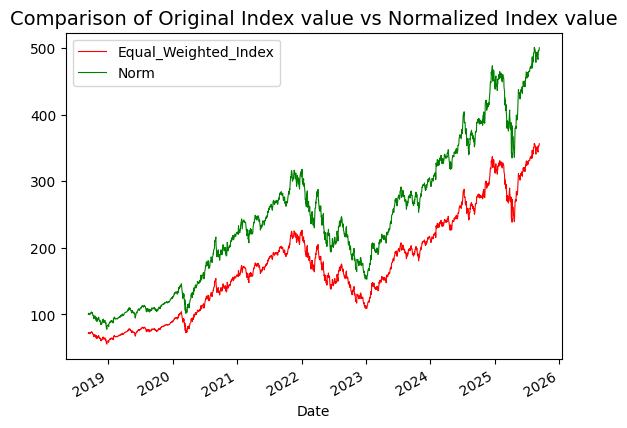

In [4]:
# 1. creating an Equal Weighted Index

# evaluate the equal weights

equal_weight = 1/len(tickers)

# create a dataframe that stores the closing prices of each stock 

close_price_df = pd.concat({ticker: c_df[f'Close'] for ticker, c_df in stock_data.items()}, axis=1)

close_price_df.columns = [f'{ticker}_Close' for ticker in stock_data.keys()] # assign proper column names

# create a new dataframe with equal-weighted closing prices 

close_eq = pd.DataFrame(close_price_df*equal_weight)

# creating the Equal weighted index dataframe

EWI = pd.DataFrame(close_eq.sum(axis=1))
EWI.columns = ['Equal_Weighted_Index']
EWI.head()

# normalize the index

base_value = 100
divisor = EWI.iloc[0]/base_value

EWI['Norm'] = EWI/divisor
print(EWI.head())

# graphical representation of the original index value vs the normalized value

EWI.plot(linewidth = 0.8, color = ('red', 'green')).set_title('Comparison of Original Index value vs Normalized Index value', fontsize = 14)
EWI.info()

In [5]:
# 1.1 construct a new dataframe considering only the normalized index value and add further technical features to it

data = pd.DataFrame(EWI['Norm']).rename(columns={'Norm': 'Index_price'})

# check and adjust for seasonality

seas_decomp = seasonal_decompose(data['Index_price'], model = 'multiplicative', period = 252)
data['deseasoned_price'] = data['Index_price']/seas_decomp.seasonal

# model returns

data['returns'] = data['deseasoned_price'].pct_change().fillna(0)

# add technical features

data['rolling_mean_20'] = data['deseasoned_price'].rolling(window=20, min_periods=1).mean()
data['rolling_mean_50'] = data['deseasoned_price'].rolling(window=50, min_periods=1).mean()

delta = data['deseasoned_price'].diff()
gain = delta.where(delta > 0, 0.0)
loss = -delta.where(delta < 0, 0.0)
avg_gain = gain.rolling(window=14, min_periods=1).mean().bfill()
avg_loss = loss.rolling(window=14).mean().bfill()
rs = avg_gain / avg_loss
data['RSI'] = 100 - (100 / (1 + rs))

data['volatility_20'] = data['returns'].rolling(window=20, min_periods=1).std().bfill()

ema_12 = data['deseasoned_price'].ewm(span=12, adjust=False).mean()
ema_26 = data['deseasoned_price'].ewm(span=26, adjust=False).mean()
data['MACD'] = ema_12 - ema_26

data.head()

,Index_price,deseasoned_price,returns,rolling_mean_20,rolling_mean_50,RSI,volatility_20,MACD
Date,,,,,,,,
2018-09-10,100.000000,97.398812,0.000000,97.398812,97.398812,0.000000,0.018160,0.000000
2018-09-11,101.503537,99.900220,0.025682,98.649516,98.649516,90.037257,0.018160,0.199543
2018-09-12,100.643862,98.865468,-0.010358,98.721500,98.721500,85.764985,0.018555,0.271061
2018-09-13,101.099906,99.261674,0.004008,98.856543,98.856543,83.960036,0.015160,0.355611
2018-09-14,101.118553,99.256982,-0.000047,98.936631,98.936631,80.723049,0.013309,0.417427


In [6]:
# 2. add macroeconomic indicators from FRED

macro = pd.DataFrame()
macro['inflation'] = web.DataReader('CPIAUCSL', 'fred', start, end).resample('B').ffill()
macro['unemployment'] = web.DataReader('UNRATE', 'fred', start, end).resample('B').ffill()
macro['gdp_growth'] = web.DataReader('A191RL1Q225SBEA', 'fred', start, end).resample('B').ffill()

# drop any existing macro columns from data before merging to avoid _x/_y suffixes

for col in macro.columns:
    if col in data.columns:
        data.drop(columns=col, inplace=True)

data = data.merge(macro, how='left', left_index=True, right_index=True).bfill()

# 2.1 adding VIX market risk sentiment

sentiment = yf.download('^VIX', start=EWI.index.min(), end=EWI.index.max())['Close'].dropna()
data['sentiment_market_risk'] = sentiment


C:\Users\sreya\AppData\Local\Temp\ipykernel_19104\2896615731.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sentiment = yf.download('^VIX', start=EWI.index.min(), end=EWI.index.max())['Close'].dropna()
[*********************100%***********************]  1 of 1 completed


In [7]:
# exponential smoothening of the Index price column
for col in ['Index_price', 'sentiment_market_risk', 'unemployment', 'inflation', 'gdp_growth']:
    data[f'{col}_smoothed'] = data[col].ewm(alpha=0.3).mean()

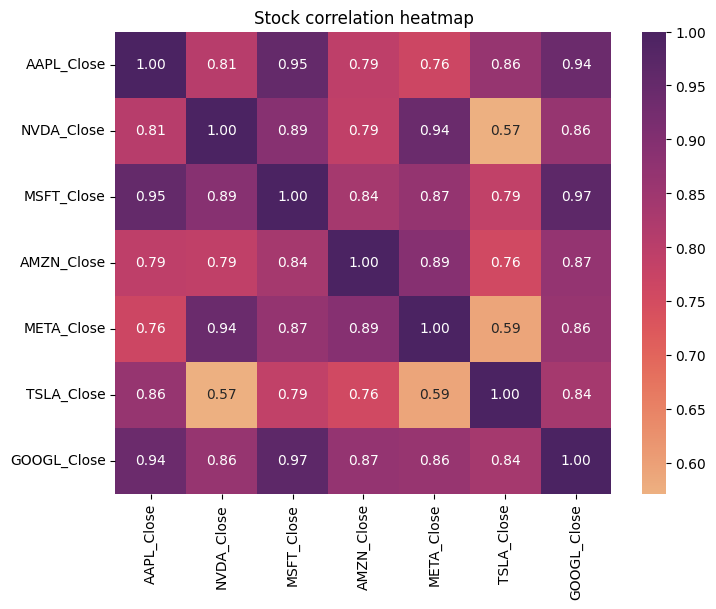

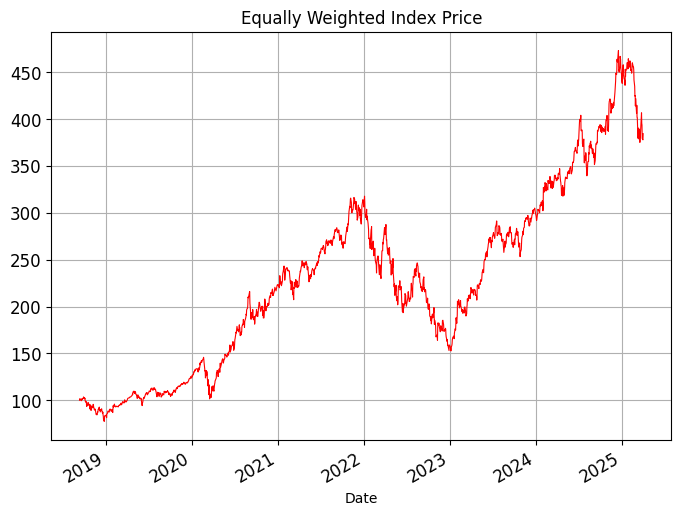

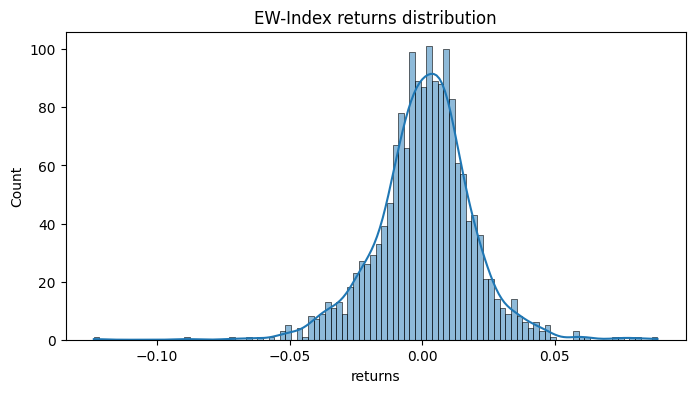

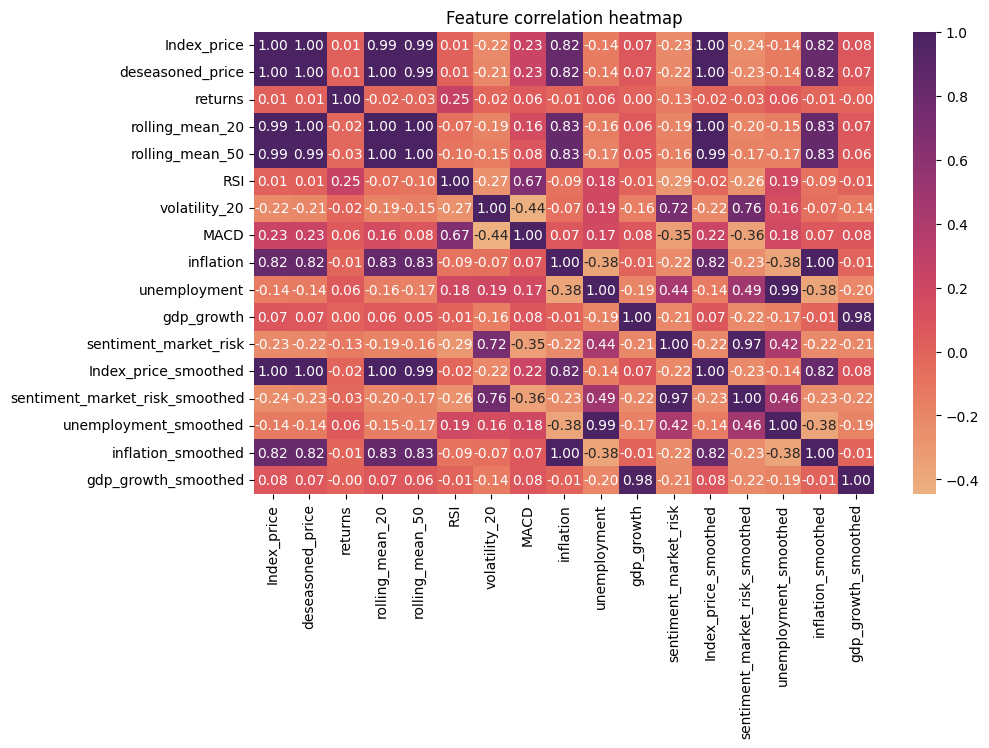

In [8]:
# data cleaning and EDA

data.dropna(inplace=True)

plt.figure(figsize=(8,6))
sns.heatmap(close_price_df.corr(), annot=True, fmt='.2f', cmap='flare')
plt.title('Stock correlation heatmap')
plt.show() 

plt.figure(figsize=(8,6))
data['Index_price'].plot(linewidth = 0.8, color = 'red', title = 'Equally Weighted Index Price', fontsize = 12, grid=True)
plt.show()

plt.figure(figsize=(8,4))
sns.histplot(data['returns'], bins=100, kde=True)
plt.title('EW-Index returns distribution')
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='flare')
plt.title('Feature correlation heatmap')
plt.show()


Mean Mae: 0.913 (0.064)
Baseline RMSE: 5.643590029221372
R^2 score: 0.9856198996051887
Accuracy of linear regressor on training set: 1.00
Accuracy of linear regressor on test set: 0.99


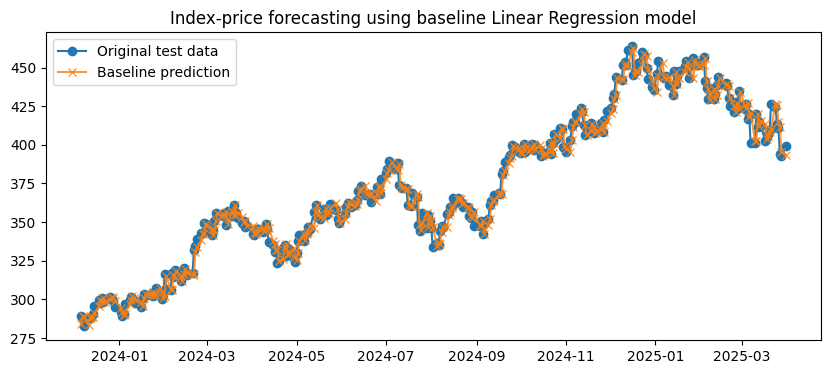

In [9]:
# 3. data normalization and creation of baseline model for forecast

scaler = StandardScaler()

data['target'] = data['deseasoned_price'].shift(-1) # we set target (y) as price of the EW-Index at t+1
data.dropna(inplace=True)
data = data.sort_index()

# picking features that will define the independent variables for model training 

features = []
for col in data.columns:
    features.append(col)
#features.remove('Index_price')
features.remove('target')

X = data[features]
y = data['target']

holdout_set = int(len(X)*0.20)
X_train_ml, X_test_ml = X[:-holdout_set], X[-holdout_set:]
y_train_ml, y_test_ml = y[:-holdout_set], y[-holdout_set:]

# normalizing data for ML application

scaler.fit(X_train_ml)
X_train = scaler.fit_transform(X_train_ml)
X_test = scaler.transform(X_test_ml)

# using linear regression as the baseline model

lin_model = LinearRegression()

scores = cross_val_score(lin_model, X_train_ml, y_train_ml, scoring='r2', cv=10, n_jobs=1)
scores = abs(scores)

#print('Cross-validation scores (10-fold):', scores)

print('Mean Mae: %.3f (%.3f)' % (scores.mean(), scores.std()))

lin_fit = lin_model.fit(X_train_ml, y_train_ml)

y_pred_lin = lin_fit.predict(X_test_ml)
r2_score_lr = r2_score(y_test_ml, y_pred_lin)
print('Baseline RMSE:', np.sqrt(mean_squared_error(y_test_ml, y_pred_lin)))
print('R^2 score:', r2_score_lr)
 
print('Accuracy of linear regressor on training set: {:.2f}'
     .format(lin_model.score(X_train_ml, y_train_ml)))
print('Accuracy of linear regressor on test set: {:.2f}'
     .format(lin_model.score(X_test_ml, y_test_ml)))


plt.figure(figsize=(10,4))
plt.plot(y_test_ml.index, y_test_ml, label = 'Original test data', marker = 'o')
plt.plot(y_test_ml.index, y_pred_lin, label= 'Baseline prediction', marker = 'x', alpha = 0.8)
plt.legend()
plt.title('Index-price forecasting using baseline Linear Regression model')
plt.show()



 Best fold is 2 with RMSE 3.768


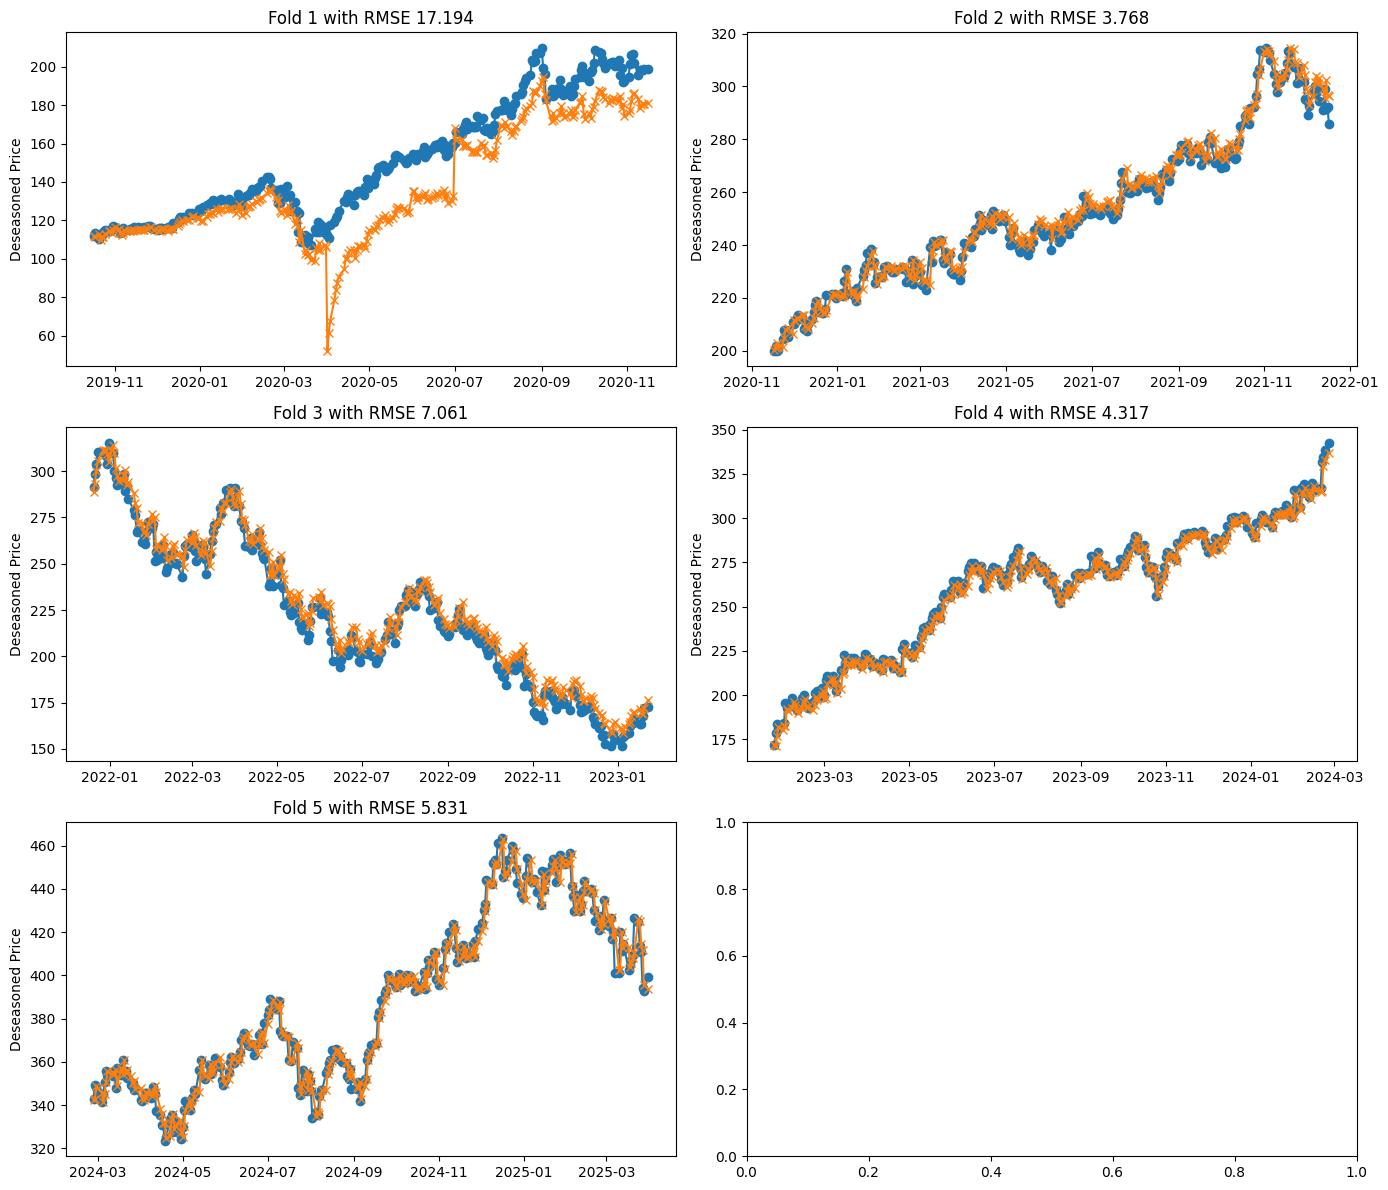

In [10]:
# using Linear Regression model with time-series split for cross validation

tscv = TimeSeriesSplit(n_splits=5, gap=7)

# preparing the subplots

n_splits = tscv.get_n_splits()
n_cols = 2
n_rows = (n_splits+1)//n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize= (14, 4*n_rows))
axes = axes.flatten()

best_fold = None
best_score = float('inf') # for RMSE, lower is better
fold_scores = []

# creating the train-test split 

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # normalizing data for ML application
    
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)
    
    # training a LR model within each fold of the time-series split

    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # predict and evaluate
    
    y_pred_lr = lr_model.predict(X_test)
    rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
    fold_scores.append(rmse_lr)

    if rmse_lr < best_score:
        best_score = rmse_lr
        best_fold = fold

    # plot of actual vs predicted for each fold

    ax = axes[fold]
    ax.plot(y_test.index, y_test, label = 'Original test data', marker = 'o')
    ax.plot(y_test.index, y_pred_lr, label = 'Predicted test data', marker = 'x')
    ax.set_title(f'Fold {fold+1} with RMSE {rmse_lr:,.3f}')
    ax.set_xlabel("")
    ax.set_ylabel('Deseasoned Price')

plt.tight_layout()
plt.show

print(f'\n Best fold is {best_fold+1} with RMSE {best_score:,.3f}')
    


In [11]:
# checking feature importance on an experimental rf model

rf = RandomForestRegressor(
    n_estimators=1000,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_raw, y_train)

importances = pd.Series(rf.feature_importances_, index=X_train_raw.columns)
importances_sorted = importances.sort_values(ascending=False)
print(importances_sorted)

Index_price_smoothed              0.783262
deseasoned_price                  0.156372
Index_price                       0.052328
rolling_mean_20                   0.006258
MACD                              0.000356
returns                           0.000189
gdp_growth_smoothed               0.000180
RSI                               0.000169
volatility_20                     0.000165
inflation_smoothed                0.000159
unemployment_smoothed             0.000156
sentiment_market_risk_smoothed    0.000152
rolling_mean_50                   0.000116
sentiment_market_risk             0.000106
inflation                         0.000012
unemployment                      0.000011
gdp_growth                        0.000010
dtype: float64


Cross-validation scores (5-fold): [4.41304166 4.92406987 1.27811946 1.95376565 0.23901225]
Mean CV R^2: 2.562 (1.812)
Test set R^2: -3.8123990463329527
Ensemble RMSE: 103.24173978890117
Ensemble MAPE: 23.22281947609293


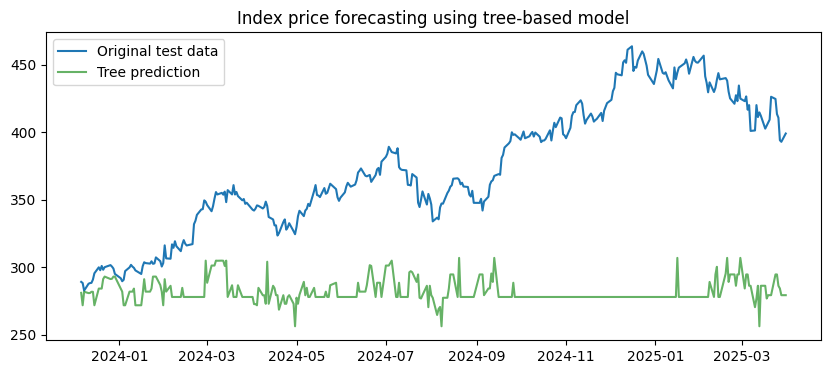

In [12]:
# 4. using a tree-based model 
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# we use a predefined parameter set as a baseline for this model and evaluate model

rfr_model = RandomForestRegressor(n_estimators=1100, random_state=57, bootstrap=False, max_depth=None, criterion='squared_error', min_samples_leaf=1, min_samples_split=2, max_features=None, n_jobs=-1)

# define a train-test holdout set

holdout_set = int(len(X)*0.20)
X_train_ml, X_test_ml = X[:-holdout_set], X[-holdout_set:]
y_train_ml, y_test_ml = y[:-holdout_set], y[-holdout_set:]

pipeline = Pipeline([('scaler_ml', StandardScaler()), ('pca', PCA(n_components=3)),('rf', rfr_model)])


rfr_scores = cross_val_score(pipeline, X_train_ml, y_train_ml, scoring='r2', cv=tscv)
rfr_scores = abs(rfr_scores)

print('Cross-validation scores (5-fold):', rfr_scores)
print('Mean CV R^2: %.3f (%.3f)' % (rfr_scores.mean(), rfr_scores.std()))

pipeline.fit(X_train_ml, y_train_ml)

y_pred_rfr = pipeline.predict(X_test_ml)

r2 = r2_score(y_test_ml, y_pred_rfr)

print('Test set R^2:', r2)
print('Ensemble RMSE:', np.sqrt(mean_squared_error(y_test_ml, y_pred_rfr)))
print('Ensemble MAPE:', np.mean(np.abs((y_test_ml - y_pred_rfr)/y_test_ml))*100)


plt.figure(figsize=(10,4))
plt.plot(y_test_ml.index, y_test_ml,label = 'Original test data')
plt.plot(y_test_ml.index, y_pred_rfr, label='Tree prediction', color = 'green', alpha = 0.6)
plt.legend()
plt.title('Index price forecasting using tree-based model')
plt.show()

We can see the Random Forest's inability to extrapolate clearly in the above plot. Even though variances around the mean have been preserved, given the feature space, the model is failing to project upward trends that progress beyond the historical range seen in training folds, which is typical of such tree based models. While the linear regression models have an explicit trens coefficient and can naturally project linearly, the forest's outputs are bound by prior label extrema. The use of PCA might also have diluted the technical indicators, for eg., we have used MACD as a feature to encapsulate time dependent momentum, however, the PCA transformation can obscure this signal for tree splitting. The -ve R^2 score on the test set is also an indicator of this that there is severe underfitting and the model performs worse than the mean as there is no true extrapolation and the trend is completely missed. This can be corrected by using a better time-aware cross validation scheme or using boosted trees or even neural network models like LSTM that better model the non-linearities and can interpolate trend better. 
We try out an XGBoost model to check for this.

In [13]:
# 5. using advanced XGBoost model for forecast after tuning hyperparameters
# model optimization using hyperopt

tscv_xg = TimeSeriesSplit(n_splits=5, gap=7)

space = {'n_estimators': hp.quniform('n_estimators', 50, 600, 10),
    'learning_rate': hp.uniform('learning_rate', 0.01, 0.30),
    'max_depth': hp.quniform('max_depth', 2, 12, 1),
    'gamma': hp.uniform('gamma', 0, 10),
    'reg_lambda': hp.uniform('reg_lambda', 10, 100),
    'subsample': hp.uniform('subsample', 0.5, 0.8),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 0.8),
    'min_child_weight': hp.quniform('min_child_weight', 1, 50, 5)}

def objective(space):
    xgb_model = XGBRegressor(n_estimators=int(space['n_estimators']),
        learning_rate=space['learning_rate'],
        max_depth=int(space['max_depth']),
        gamma = space['gamma'],
        reg_lambda = space['reg_lambda'],
        subsample = space['subsample'],
        colsample_bytree = space['colsample_bytree'],
        min_child_weight = int(space['min_child_weight']),
        random_state = 42,
        n_jobs = -1)

    r2_scores = []
    rmse_scores = []
    

    # creating the train-test split 

    for train_idx, test_idx in tscv_xg.split(X):
       X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
       y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # normalizing data for ML application

       scaler_xg = StandardScaler()
       X_train = scaler_xg.fit_transform(X_train_raw)
       X_test = scaler_xg.transform(X_test_raw)

       xgb_model.fit(X_train, y_train)
       pred = xgb_model.predict(X_test)

       r2_scores.append(r2_score(y_test, pred))
       rmse_scores.append(np.sqrt(mean_squared_error(y_test, pred)))
    
    avg_r2 = np.mean(r2_scores)
    avg_rmse = np.mean(rmse_scores)
    
    print(f"R²: {avg_r2:.4f}, RMSE: {avg_rmse:.4f}")

    return {'loss': avg_rmse, 'status': STATUS_OK}

# optimization algorithm

trials = Trials()

best_hyperparams = fmin(fn = objective, space = space, algo= tpe.suggest, max_evals = 500, trials = trials)

print("The best hyperparameters are : ","\n")
print(best_hyperparams)

R²: -1.6159, RMSE: 45.4702                             
R²: -1.9131, RMSE: 47.2123                                                      
R²: -2.4691, RMSE: 51.0541                                                      
R²: -1.5354, RMSE: 44.1983                                                      
R²: -1.5747, RMSE: 44.7451                                                      
R²: -1.7378, RMSE: 45.9983                                                      
R²: -1.5723, RMSE: 44.4720                                                      
R²: -1.6204, RMSE: 44.6324                                                      
R²: -1.8735, RMSE: 46.7802                                                      
R²: -1.6600, RMSE: 45.4513                                                      
R²: -1.7946, RMSE: 46.7242                                                       
R²: -1.6556, RMSE: 45.3495                                                       
R²: -3.4793, RMSE: 59.3861                         

As expected, the XGBoost model performs significantly better than the forest even with a simple time series split. The performance can be enhanced by using a more sophisticated time series split like walk-forward validation or rolling validation.

In [14]:
# using the best hyperparameters to create our new model and predicting 

best_params = {
    'max_depth': int(best_hyperparams['max_depth']),
    'learning_rate': best_hyperparams['learning_rate'],
    'subsample': best_hyperparams['subsample'],
    'colsample_bytree': best_hyperparams['colsample_bytree'],
    'gamma': best_hyperparams['gamma'],
    'min_child_weight': int(best_hyperparams['min_child_weight']),
    'n_estimators': int(best_hyperparams['n_estimators']),  
    'random_state': 42,
    'n_jobs': -1
}

reg_xgb = XGBRegressor(**best_params)
reg_xgb.fit(X_train, y_train)

y_pred = reg_xgb.predict(X_test)
r2_score_xgb = r2_score(y_test, y_pred)
print('Model RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R^2 score:', r2_score_xgb)


Model RMSE: 82.43684618643456
R^2 score: -3.5884585670381455


However, as we see above, even the XGBoost model gives us a -ve r2 score which can be attributed to the fact that our dataset is highly transformed, first we have built an equally weighted index out of actual stock prices, and we do not have a very rich feature space, the trend is well explained by the linear model but as soon as we involve complex models, we get anomalies. This shows that we do not need such complex models for our dataset and the simple LR model with time-series split is more than enough to track our index and provide near-accurate predictions.